In [ ]:
import os
import platform
import torch

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("Runtime working:", os.path.exists("/content"))

Python: 3.13.16
PyTorch: 2.11.0+cpu
GPU available: False
Runtime working: True


In [ ]:
%pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 8.3 MB/s eta 0:00:00


In [ ]:
import ultralytics

print("Ultralytics version:", ultralytics.__version__)
print("Setup successful!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.182
Setup successful!


In [ ]:
!git clone https://github.com/luischuquim/BananaRipeness.git

Cloning into 'BananaRipeness'...
remote: Enumerating objects: 188805, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 188805 (delta 4), reused 0 (delta 0), pack-reused 188794 (from 4)
Receiving objects: 100% (188805/188805), 15.73 GiB | 23.15 MiB/s, done.
Resolving deltas: 100% (118/118), done.
Updating files: 100% (189243/189243), done.


In [ ]:
import os

dataset_path = "/content/BananaRipeness/Banana Images/Real Dataset"

print("Dataset folder exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    print("Contents:", os.listdir(dataset_path))

Dataset folder exists: True
Contents: ['validation', 'train', 'test']


In [ ]:
import os

dataset_path = "/content/BananaRipeness/Banana Images/Real Dataset"

for split in ["train", "validation", "test"]:
    split_path = os.path.join(dataset_path, split)
    print(f"\n{split.upper()}")

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            image_count = sum(
                1 for f in os.listdir(class_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
            )
            print(f"  {class_name}: {image_count} images")


TRAIN
  Class A: 857 images
  Class B: 489 images
  Class C: 335 images
  Class D: 415 images

VALIDATION
  Class A: 286 images
  Class B: 163 images
  Class C: 112 images
  Class D: 139 images

TEST
  Class A: 286 images
  Class B: 163 images
  Class C: 112 images
  Class D: 138 images


In [ ]:
import os
import shutil

source = "/content/BananaRipeness/Banana Images/Real Dataset"
destination = "/content/banana_yolo_data"

splits = {
    "train": "train",
    "validation": "val",
    "test": "test"
}

for source_split, target_split in splits.items():
    source_split_path = os.path.join(source, source_split)
    target_split_path = os.path.join(destination, target_split)

    os.makedirs(target_split_path, exist_ok=True)

    for class_name in os.listdir(source_split_path):
        class_source = os.path.join(source_split_path, class_name)
        class_target = os.path.join(target_split_path, class_name)

        if os.path.isdir(class_source):
            shutil.copytree(
                class_source,
                class_target,
                dirs_exist_ok=True
            )

print("Dataset preparation complete!")

for split in ["train", "val", "test"]:
    split_path = os.path.join(destination, split)
    print(f"{split}: {os.listdir(split_path)}")

Dataset preparation complete!
train: ['Class C', 'Class A', 'Class D', 'Class B']
val: ['Class C', 'Class A', 'Class D', 'Class B']
test: ['Class C', 'Class A', 'Class D', 'Class B']


In [ ]:
import os

dataset_path = "/content/banana_yolo_data"

for split in ["train", "val", "test"]:
    split_path = os.path.join(dataset_path, split)
    total = 0

    print(f"\n{split.upper()}")

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            count = sum(
                1 for f in os.listdir(class_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
            )
            total += count
            print(f"{class_name}: {count}")

    print("Total:", total)


TRAIN
Class A: 857
Class B: 489
Class C: 335
Class D: 415
Total: 2096

VAL
Class A: 286
Class B: 163
Class C: 112
Class D: 139
Total: 700

TEST
Class A: 286
Class B: 163
Class C: 112
Class D: 138
Total: 699


In [ ]:
from ultralytics import YOLO
import torch

print("Using CPU:", not torch.cuda.is_available())

model = YOLO("yolov8n-cls.pt")

results = model.train(
    data="/content/banana_yolo_data",
    epochs=30,
    imgsz=224,
    batch=8,
    device="cpu",
    workers=2,
    project="/content/banana_results",
    name="original_model",
    patience=7,
    seed=42,
    plots=True
)

Using CPU: True
Ultralytics 8.4.182 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/banana_yolo_data, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=original_model, nbs=64, nms=None, opset=N

In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/banana_results/original_model/weights/best.pt"
)

results = model.val(
    data="/content/banana_yolo_data",
    split="test",
    imgsz=224,
    batch=8,
    device="cpu",
    project="/content/banana_results",
    name="original_model_test"
)

print("Test Top-1 Accuracy:", results.top1)
print("Test Top-5 Accuracy:", results.top5)

Ultralytics 8.4.182 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv8n-cls summary (fused): 30 layers, 1,440,004 parameters, 0 gradients, 3.3 GFLOPs
train: /content/banana_yolo_data/train... found 2096 images in 4 classes ✅ 
val: /content/banana_yolo_data/val... found 700 images in 4 classes ✅ 
test: /content/banana_yolo_data/test... found 699 images in 4 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 353.1±127.8 MB/s, size: 92.9 KB)
test: Scanning /content/banana_yolo_data/test... 699 images, 0 corrupt: 100% ━━━━━━━━━━━━ 699/699 2.2Kit/s 0.3s
test: New cache created: /content/banana_yolo_data/test.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 88/88 8.0it/s 11.0s
                   all      0.914          1
Speed: 0.0ms preprocess, 11.8ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/banana_results/original_model_test
Test Top-1 Accuracy: 0.9141631126403809
Test Top-5 Accuracy: 1.0


In [ ]:
import os
import json
import shutil

from zipfile import ZipFile, ZIP_DEFLATED

project_dir = "/content/banana_project"
model_path = "/content/banana_results/original_model/weights/best.pt"
zip_path = "/content/banana_project_backup.zip"

os.makedirs(project_dir, exist_ok=True)

# Save the trained model
shutil.copy2(
    model_path,
    os.path.join(project_dir, "best.pt")
)

# Save the model details
summary = {
    "model": "YOLOv8n-cls",
    "dataset": "Original BananaRipeness Real Dataset",
    "classes": ["Class A", "Class B", "Class C", "Class D"],
    "validation_accuracy": 0.917,
    "test_accuracy": 0.9141631126403809,
    "test_top5_accuracy": 1.0,
    "epochs_completed": 19,
    "best_epoch": 12,
    "image_size": 224
}

with open(os.path.join(project_dir, "model_summary.json"), "w") as f:
    json.dump(summary, f, indent=4)

# Create downloadable ZIP
with ZipFile(zip_path, "w", ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(project_dir):
        for filename in files:
            full_path = os.path.join(root, filename)
            zipf.write(full_path, os.path.relpath(full_path, project_dir))

print("Backup created:", zip_path)
print("Model size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")

Backup created: /content/banana_project_backup.zip
Model size: 2.83 MB


In [ ]:
from google.colab import files
files.download("/content/banana_project_backup.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
!git clone https://github.com/luischuquim/BananaRipeness.git

import os

repo = "/content/BananaRipeness"

for root, dirs, files in os.walk(repo):
    dirs[:] = [d for d in dirs if d not in [".git"]]
    depth = root.replace(repo, "").count(os.sep)

    if depth <= 3:
        print(root, "->", dirs[:8], "| files:", files[:5])

Cloning into 'BananaRipeness'...
remote: Enumerating objects: 188805, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 188805 (delta 4), reused 0 (delta 0), pack-reused 188794 (from 4)
Receiving objects: 100% (188805/188805), 15.73 GiB | 35.31 MiB/s, done.
Resolving deltas: 100% (118/118), done.
Updating files: 100% (189243/189243), done.
/content/BananaRipeness -> ['Banana Images'] | files: ['404_LIME_0_7 (3).png', 'sintetica.png', 'CITATION.cff', 'real.png', '404_LIME_0_6 (3).png']
/content/BananaRipeness/Banana Images -> ['varying illumination', 'Real Dataset', 'Synthetic Dataset'] | files: []
/content/BananaRipeness/Banana Images/varying illumination -> ['dataset Real ref LIME 0_7', 'dataset Real ref LIME 0_5', 'dataset Real ref LIME 0_1', 'dataset Real ref LIME 0_6', 'dataset Real ref LIME 0_4', 'dataset Real ref LIME 0_3', 'dataset Real ref LIME 0_2'] | files: []
/content/BananaRipeness/Banana Images/varying illumi

In [2]:
import os

repo = "/content/BananaRipeness"

print("Repository exists:", os.path.exists(repo))

for root, dirs, files in os.walk(repo):
    dirs[:] = [d for d in dirs if d != ".git"]

    image_count = sum(
        f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        for f in files
    )

    if image_count > 0 or "dataset" in root.lower():
        print(f"{root} | images: {image_count} | subfolders: {dirs[:6]}")

Repository exists: True
/content/BananaRipeness | images: 10 | subfolders: ['Banana Images']
/content/BananaRipeness/Banana Images/varying illumination/dataset Real ref LIME 0_7 | images: 0 | subfolders: ['validation', 'train', 'test']
/content/BananaRipeness/Banana Images/varying illumination/dataset Real ref LIME 0_7/validation | images: 0 | subfolders: ['Class C', 'Class B', 'Class D', 'Class A']
/content/BananaRipeness/Banana Images/varying illumination/dataset Real ref LIME 0_7/validation/Class C | images: 112 | subfolders: []
/content/BananaRipeness/Banana Images/varying illumination/dataset Real ref LIME 0_7/validation/Class B | images: 163 | subfolders: []
/content/BananaRipeness/Banana Images/varying illumination/dataset Real ref LIME 0_7/validation/Class D | images: 139 | subfolders: []
/content/BananaRipeness/Banana Images/varying illumination/dataset Real ref LIME 0_7/validation/Class A | images: 286 | subfolders: []
/content/BananaRipeness/Banana Images/varying illuminatio

In [3]:
%pip install -q ultralytics

In [4]:
from ultralytics import YOLO
print("Ultralytics installed successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics installed successfully!


In [5]:
import os
from google.colab import files
from ultralytics import YOLO

# 1. Locate the saved model
MODEL_PATH = "/content/best.pt"

if not os.path.exists(MODEL_PATH):
    print("Please upload your saved best.pt model.")
    uploaded = files.upload()

    if "best.pt" not in uploaded:
        raise FileNotFoundError(
            "Please upload the file named best.pt."
        )

# 2. Select the original real-image dataset
DATASET_PATH = (
    "/content/BananaRipeness/Banana Images/Real Dataset"
)

assert os.path.isdir(DATASET_PATH), "Dataset folder not found!"
assert os.path.isdir(os.path.join(DATASET_PATH, "test")), (
    "Test folder not found!"
)

# 3. Load the trained model
model = YOLO(MODEL_PATH)

print("Model loaded successfully.")
print("Model classes:", model.names)

# 4. Evaluate on the held-out test set
results = model.val(
    data=DATASET_PATH,
    split="test",
    imgsz=224,
    batch=8,
    device="cpu",
    plots=True,
    verbose=True
)

# 5. Display the main results
print("\n========== TEST RESULTS ==========")
print(f"Top-1 Accuracy: {results.top1:.4f}")
print(f"Top-5 Accuracy: {results.top5:.4f}")
print("==================================")

Please upload your saved best.pt model.


Saving best.pt to best.pt
Model loaded successfully.
Model classes: {0: 'Class A', 1: 'Class B', 2: 'Class C', 3: 'Class D'}
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv8n-cls summary (fused): 30 layers, 1,440,004 parameters, 0 gradients, 3.3 GFLOPs
train: /content/BananaRipeness/Banana Images/Real Dataset/train... found 2096 images in 4 classes ✅ 
val: /content/BananaRipeness/Banana Images/Real Dataset/validation... found 700 images in 4 classes ✅ 
test: /content/BananaRipeness/Banana Images/Real Dataset/test... found 699 images in 4 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 101.8±91.2 MB/s, size: 92.9 KB)
test: Scanning /content/BananaRipeness/Banana Images/Real Dataset/test... 699 images, 0 corrupt: 100% ━━━━━━━━━━━━ 699/699 1.1Kit/s 0.7s
test: New cache created: /content/BananaRipeness/Banana Images/Real Dataset/test.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 88/88 7.0it/s 12.6s
           

Test images evaluated: 699
Accuracy: 0.9142


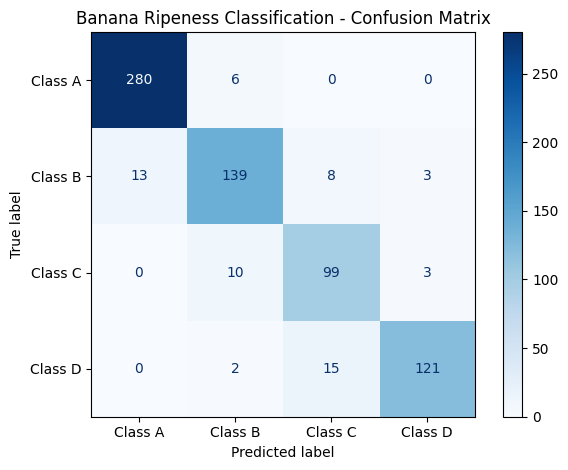

,precision,recall,f1-score,support
Class A,0.9556,0.9790,0.9672,286.0000
Class B,0.8854,0.8528,0.8688,163.0000
Class C,0.8115,0.8839,0.8462,112.0000
Class D,0.9528,0.8768,0.9132,138.0000
accuracy,0.9142,0.9142,0.9142,0.9142
macro avg,0.9013,0.8981,0.8988,699.0000
weighted avg,0.9156,0.9142,0.9142,699.0000


Saved: /content/classification_report.csv
Saved: /content/confusion_matrix.png


In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score
)
from ultralytics import YOLO

model = YOLO("/content/best.pt")

test_dir = (
    "/content/BananaRipeness/"
    "Banana Images/Real Dataset/test"
)

class_names = ["Class A", "Class B", "Class C", "Class D"]
y_true, y_pred = [], []

# Predict every labelled test image
for true_label, class_name in enumerate(class_names):
    class_dir = os.path.join(test_dir, class_name)

    for filename in os.listdir(class_dir):
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):
            image_path = os.path.join(class_dir, filename)
            result = model.predict(
                source=image_path,
                imgsz=224,
                device="cpu",
                verbose=False
            )[0]

            y_true.append(true_label)
            y_pred.append(int(result.probs.top1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Test images evaluated:", len(y_true))
print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")

# Confusion matrix
cm = confusion_matrix(
    y_true, y_pred,
    labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Banana Ripeness Classification - Confusion Matrix")
plt.tight_layout()
plt.savefig("/content/confusion_matrix.png", dpi=300)
plt.show()

# Per-class report
report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

df = pd.DataFrame(report).transpose()
display(df.round(4))

df.to_csv("/content/classification_report.csv")
print("Saved: /content/classification_report.csv")
print("Saved: /content/confusion_matrix.png")

In [7]:
from google.colab import files

files.download("/content/confusion_matrix.png")
files.download("/content/classification_report.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:

import os, glob

print("Searching for training history and plots...\n")

csv_files = glob.glob("/content/**/results.csv", recursive=True)
plot_files = glob.glob("/content/**/*.png", recursive=True)

print("TRAINING CSV FILES:")
for f in csv_files:
    print(f)

print("\nEXISTING PNG PLOTS:")
for f in plot_files:
    print(f)


Streaming output truncated to the last 5000 lines.
/content/BananaRipeness/Banana Images/Synthetic Dataset/test/Ripeness B/3 bananas/TipoB2_3_Celeste_PF_DD0021.png
/content/BananaRipeness/Banana Images/Synthetic Dataset/test/Ripeness B/3 bananas/TipoB2_3_Celeste_M_DD0019.png
/content/BananaRipeness/Banana Images/Synthetic Dataset/test/Ripeness B/3 bananas/TipoB1_3_Celeste_M_DI0018.png
/content/BananaRipeness/Banana Images/Synthetic Dataset/test/Ripeness B/3 bananas/TipoB1_3_Wall_P_V0005.png
/content/BananaRipeness/Banana Images/Synthetic Dataset/test/Ripeness B/3 bananas/TipoB1_3_Morado_FM_V0007.png
/content/BananaRipeness/Banana Images/Synthetic Dataset/test/Ripeness B/3 bananas/TipoB1_3_Concrete_FM_DI0016.png
/content/BananaRipeness/Banana Images/Synthetic Dataset/test/Ripeness B/3 bananas/TipoB1_3_Celeste_P_V0027.png
/content/BananaRipeness/Banana Images/Synthetic Dataset/test/Ripeness B/3 bananas/TipoB2_3_Asset_F_DI0015.png
/content/BananaRipeness/Banana Images/Synthetic Dataset/te

In [10]:

import os, glob
import pandas as pd
import matplotlib.pyplot as plt

csv_files = glob.glob("/content/**/results.csv", recursive=True)

if not csv_files:
    print("No results.csv found. Keep Colab open and tell me.")
else:
    csv_path = max(csv_files, key=os.path.getmtime)
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    print("Using:", csv_path)
    print("Available columns:", df.columns.tolist())
    display(df.head())

    # Plot accuracy metrics if available
    acc_cols = [
        c for c in df.columns
        if "accuracy" in c.lower() or "acc" in c.lower()
    ]

    if acc_cols:
        plt.figure(figsize=(8, 5))
        for c in acc_cols:
            plt.plot(df.index + 1, df[c], marker="o", label=c)
        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.title("Banana Model: Accuracy Across Epochs")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.savefig("/content/training_accuracy.png", dpi=200)
        plt.show()
    else:
        print("No accuracy columns found in this CSV.")

    # Plot loss metrics if available
    loss_cols = [
        c for c in df.columns if "loss" in c.lower()
    ]

    if loss_cols:
        plt.figure(figsize=(8, 5))
        for c in loss_cols:
            plt.plot(df.index + 1, df[c], marker="o", label=c)
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title("Banana Model: Loss Across Epochs")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.savefig("/content/training_loss.png", dpi=200)
        plt.show()
    else:
        print("No loss columns found in this CSV.")


No results.csv found. Keep Colab open and tell me.


In [11]:

import os
from pathlib import Path

roots = [
    Path("/content"),
    Path("/content/banana_results"),
    Path("/content/runs"),
]

found = []

for root in roots:
    if root.exists():
        for p in root.rglob("*"):
            if p.is_file() and (
                p.name == "results.csv"
                or p.name.startswith("results")
                or p.name in ["args.yaml", "confusion_matrix.png",
                              "results.png", "BoxF1_curve.png"]
            ):
                found.append(str(p))

print("Matching files:")
if found:
    for p in sorted(set(found)):
        print(p)
else:
    print("No matching files found.")


Matching files:
/content/confusion_matrix.png
/content/runs/classify/val/confusion_matrix.png


In [13]:

import os

paths = {
    "Trained model": "/content/best.pt",
    "Banana dataset": "/content/BananaRipeness/Banana Images/Real Dataset",
    "Classification report": "/content/classification_report.csv",
    "Confusion matrix": "/content/confusion_matrix.png",
}

for name, path in paths.items():
    print(f"{name}: {'FOUND' if os.path.exists(path) else 'NOT FOUND'}")
    if os.path.isdir(path):
        print("  Subfolders:", os.listdir(path))


Trained model: FOUND
Banana dataset: FOUND
  Subfolders: ['validation', 'train', 'test.cache', 'test']
Classification report: FOUND
Confusion matrix: FOUND


In [14]:

import os, zipfile

files_to_save = [
    "/content/confusion_matrix.png",
    "/content/runs/classify/val/confusion_matrix.png",
    "/content/classification_report.csv",
]

zip_path = "/content/banana_results_backup.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in files_to_save:
        if os.path.isfile(path):
            z.write(path, arcname=os.path.basename(path))

print("Backup created:", zip_path)

from google.colab import files
files.download(zip_path)


Backup created: /content/banana_results_backup.zip


/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'confusion_matrix.png'
  return self._open_to_write(zinfo, force_zip64=force_zip64)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Test images found: 699


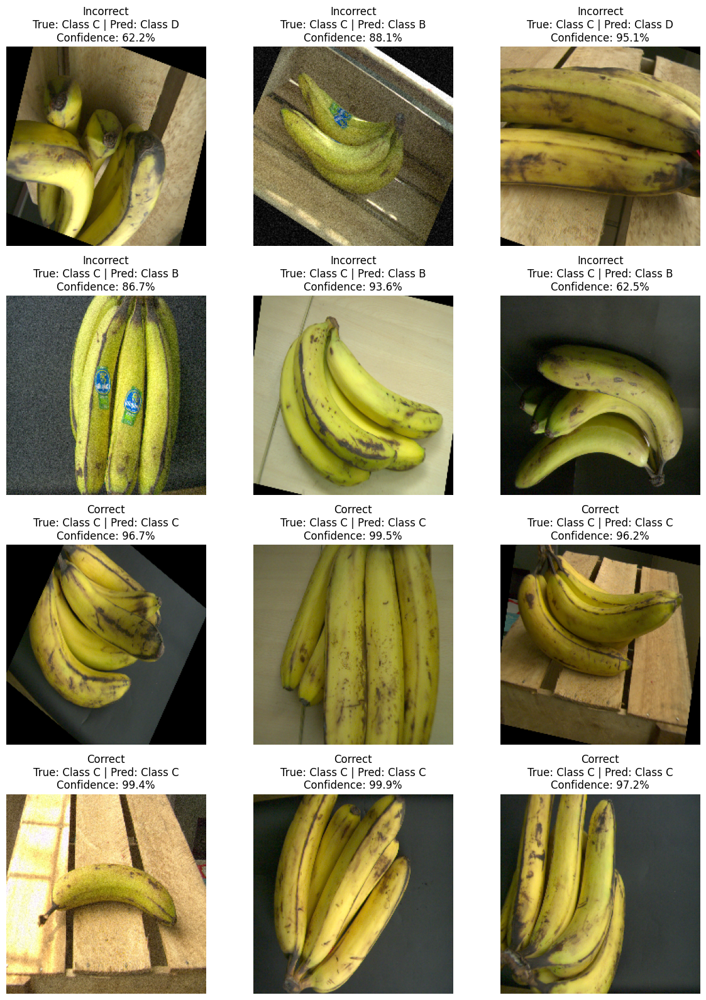

Gallery saved: /content/banana_results_latest/prediction_gallery.png

Backup ready: /content/banana_results_latest.zip


In [15]:

from ultralytics import YOLO
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd
import zipfile, os, random

# Paths
dataset = Path("/content/BananaRipeness/Banana Images/Real Dataset/test")
model_path = "/content/best.pt"
output_dir = Path("/content/banana_results_latest")
output_dir.mkdir(exist_ok=True)

# Load model and gather test images
model = YOLO(model_path)
image_paths = [
    p for p in dataset.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
]

print("Test images found:", len(image_paths))

# Predict in batches
results = model.predict(
    source=[str(p) for p in image_paths],
    imgsz=224,
    batch=16,
    device="cpu",
    verbose=False
)

records = []
for path, result in zip(image_paths, results):
    true_class = path.parent.name
    pred_index = int(result.probs.top1)
    pred_class = str(model.names[pred_index])
    confidence = float(result.probs.top1conf)

    records.append({
        "path": str(path),
        "true": true_class,
        "predicted": pred_class,
        "confidence": confidence,
        "correct": true_class == pred_class
    })

df = pd.DataFrame(records)
df.to_csv(output_dir / "test_predictions.csv", index=False)

# Prefer misclassified examples, then correct examples
wrong = df[~df["correct"]].head(6)
right = df[df["correct"]].head(6)
chosen = pd.concat([wrong, right]).reset_index(drop=True)

if len(chosen) == 0:
    print("No images available for the gallery.")
else:
    cols = 3
    rows = (len(chosen) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows))
    axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, chosen.iterrows()):
        img = Image.open(row["path"]).convert("RGB")
        ax.imshow(img)
        status = "Correct" if row["correct"] else "Incorrect"
        ax.set_title(
            f"{status}\nTrue: {row['true']} | Pred: {row['predicted']}\n"
            f"Confidence: {row['confidence']:.1%}"
        )
        ax.axis("off")

    plt.tight_layout()
    gallery_path = output_dir / "prediction_gallery.png"
    plt.savefig(gallery_path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Gallery saved:", gallery_path)

# Create a ZIP with unique names
zip_path = "/content/banana_results_latest.zip"
files_to_add = [
    ("/content/confusion_matrix.png", "confusion_matrix_custom.png"),
    ("/content/runs/classify/val/confusion_matrix.png",
     "confusion_matrix_ultralytics.png"),
    ("/content/classification_report.csv", "classification_report.csv"),
    (str(output_dir / "prediction_gallery.png"), "prediction_gallery.png"),
    (str(output_dir / "test_predictions.csv"), "test_predictions.csv"),
    (model_path, "best.pt"),
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for source, archive_name in files_to_add:
        if os.path.isfile(source):
            z.write(source, arcname=archive_name)

print("\nBackup ready:", zip_path)


In [16]:

from google.colab import files
files.download("/content/banana_results_latest.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
import os

check = [
    "/content/banana_results_latest/prediction_gallery.png",
    "/content/banana_results_latest/test_predictions.csv",
    "/content/banana_results_latest.zip",
]

for p in check:
    print(("FOUND  " if os.path.exists(p) else "MISSING"), p)

FOUND   /content/banana_results_latest/prediction_gallery.png
FOUND   /content/banana_results_latest/test_predictions.csv
FOUND   /content/banana_results_latest.zip


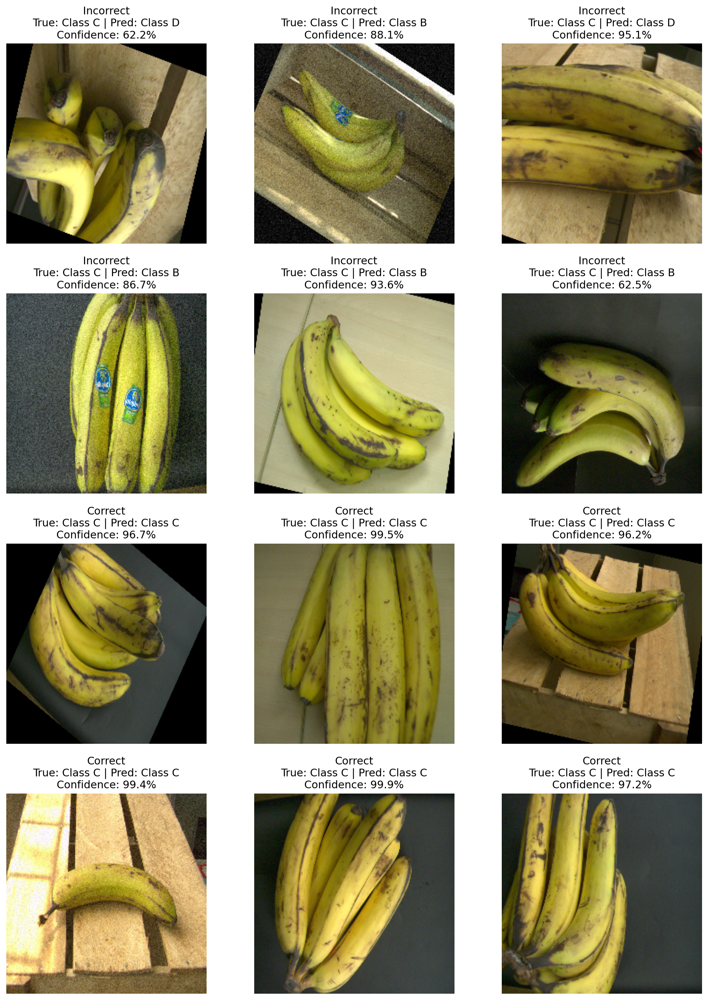

In [18]:
from IPython.display import display, Image
display(Image(filename="/content/banana_results_latest/prediction_gallery.png"))

In [19]:
from google.colab import files
files.download("/content/banana_results_latest/prediction_gallery.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
import os

for p in [
    "/content/best.pt",
    "/content/BananaRipeness/Banana Images/Real Dataset",
    "/content/banana_results_latest.zip",
]:
    print(("FOUND: " if os.path.exists(p) else "MISSING: ") + p)

FOUND: /content/best.pt
FOUND: /content/BananaRipeness/Banana Images/Real Dataset
FOUND: /content/banana_results_latest.zip


In [21]:

from pathlib import Path

roots = [
    Path("/content"),
    Path("/content/banana_results_latest"),
    Path("/content/runs"),
]

for root in roots:
    if root.exists():
        for p in root.rglob("*"):
            if p.is_file() and p.name in [
                "results.csv",
                "results.png",
                "args.yaml",
                "best.pt",
                "last.pt",
            ]:
                print(p)


/content/best.pt


In [22]:

from ultralytics import YOLO
from pathlib import Path
import os

data_path = "/content/BananaRipeness/Banana Images/Real Dataset"
model_path = "/content/best.pt"

assert os.path.isfile(model_path), "Model file not found"
assert os.path.isdir(data_path), "Dataset folder not found"

model = YOLO(model_path)

results = model.train(
    data=data_path,
    epochs=30,
    patience=7,
    imgsz=224,
    batch=8,
    device="cpu",
    project="/content/banana_curve_training",
    name="fine_tune",
    exist_ok=True,
    plots=True
)

print("\nTraining finished.")
print("Training history:", "/content/banana_curve_training/fine_tune/results.csv")
print("Training plots:", "/content/banana_curve_training/fine_tune/results.png")


Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/BananaRipeness/Banana Images/Real Dataset, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fine_tune, nbs=64, nms=None, op

KeyboardInterrupt: 

In [ ]:

import os
import zipfile
from pathlib import Path

# Folders/files to preserve
items = [
    Path("/content/BananaRipeness"),
    Path("/content/banana_results"),
    Path("/content/banana_results_latest"),
    Path("/content/runs"),
    Path("/content/best.pt"),
    Path("/content/yolov8n.pt"),
    Path("/content/confusion_matrix.png"),
    Path("/content/classification_report.csv"),
]

zip_path = "/content/banana_project_full_backup.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for item in items:
        if not item.exists():
            continue

        if item.is_file():
            z.write(item, arcname=item.name)
        else:
            for file in item.rglob("*"):
                if file.is_file():
                    z.write(file, arcname=str(file.relative_to("/content")))

print("Backup created:", zip_path)
print("Size (MB):", round(os.path.getsize(zip_path) / (1024**2), 2))


In [ ]:

from google.colab import files
files.download("/content/banana_project_full_backup.zip")
